In [ ]:
# ============================================================
# Install Required Libraries
# ============================================================

!pip install torch torchvision torchaudio --quiet
!pip install numpy pandas matplotlib scikit-learn einops tqdm --quiet

In [13]:
# Most of these ship pre-installed on Colab; this just guarantees consistent versions.
!pip install -q einops


In [28]:
import warnings
warnings.filterwarnings("ignore")

import os
import math
import time
import random
import json as pyjson

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Torch version:", torch.__version__)


Torch version: 2.11.0+cu128


In [29]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Random seed set to {SEED}")


Random seed set to 42


In [30]:
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


CUDA available: True
GPU name: Tesla T4
Using device: cuda


In [31]:
from google.colab import files

uploaded = files.upload()   # a file picker will pop up — select Xiatang.csv
DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

Saving Xiatang.csv to Xiatang (2).csv


In [32]:
# Dataset shape
print("Dataset shape:", df.shape)
print("\nStation(s):", df["name"].unique())
print("Date range:", df["time"].min(), "to", df["time"].max())


Dataset shape: (6946, 11)

Station(s): ['峡塘']
Date range: 2020/12/17 20:00 to 2025/9/9 8:00


In [33]:
# Missing values
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
name,0,0.00
time,0,0.00
TEMP,50,0.72
pH,41,0.59
DO,42,0.60
EC,69,0.99
EUR,70,1.01
COMMn,179,2.58
NH3-N,54,0.78
TP,46,0.66


In [34]:
# Descriptive statistics
feature_cols = ["TEMP", "pH", "DO", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN"]
df[feature_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
TEMP,6896.0,8.115222,5.799623,0.03000,1.700000,8.400000,13.515625,23.03440
pH,6905.0,8.496987,0.196361,7.85000,8.370000,8.488660,8.689670,8.94000
DO,6904.0,10.378211,1.832092,3.62000,9.116722,10.502375,11.748530,14.17000
EC,6877.0,464.561032,43.124351,1.00000,435.000000,466.606800,498.698200,535.16000
EUR,6876.0,97.869520,259.554776,0.60559,15.686203,40.000000,96.000000,9999.00000
COMMn,6767.0,1.484044,1.787360,0.25000,0.746780,1.167110,1.604510,26.16647
NH3-N,6892.0,0.059486,0.134242,0.02000,0.025000,0.025000,0.047573,2.08266
TP,6900.0,0.009472,0.019197,0.00000,0.005000,0.005000,0.008920,0.45770
TN,6861.0,1.336473,0.333450,0.05000,1.181810,1.291880,1.432300,9.33475


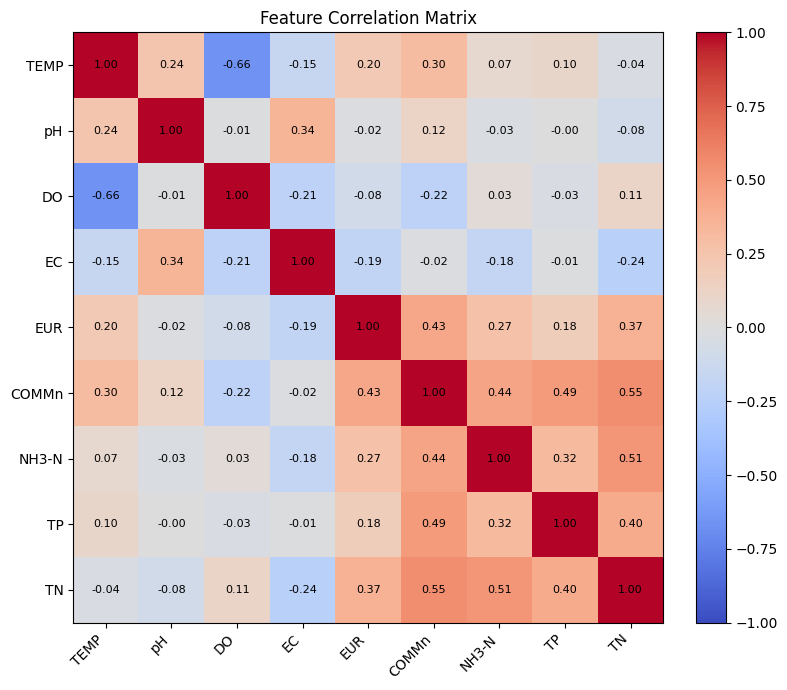

In [35]:
# Correlation matrix
plt.figure(figsize=(9, 7))
corr = df[feature_cols].corr()
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(feature_cols)), feature_cols, rotation=45, ha="right")
plt.yticks(range(len(feature_cols)), feature_cols)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [38]:
# Resample to a regular 4-hour interval (median native sampling interval in the raw data is 4h)

# Defensive: ensure "time" is actually datetime before indexing (handles reruns/out-of-order execution)
df["time"] = pd.to_datetime(df["time"])

df_ts = df.set_index("time")[feature_cols].copy()
print("Index type:", type(df_ts.index))  # should say DatetimeIndex

# Coerce to numeric — some rows may contain stray non-numeric values (sensor codes, "N/A", etc.)
for col in feature_cols:
    df_ts[col] = pd.to_numeric(df_ts[col], errors="coerce")

df_reg = df_ts.resample("4h").mean()

print("Before resampling:", df_ts.shape)
print("After resampling to 4H grid:", df_reg.shape)
print("Missing after resampling:\n", df_reg.isna().sum())

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Before resampling: (6946, 9)
After resampling to 4H grid: (10884, 9)
Missing after resampling:
 TEMP     3990
pH       3981
DO       3982
EC       4009
EUR      4010
COMMn    4119
NH3-N    3994
TP       3986
TN       4025
dtype: int64


In [39]:
# Handle missing values: forward fill, then backward fill for any leading NaNs,
# then linear interpolation as a final safeguard
df_reg = df_reg.ffill().bfill()
df_reg = df_reg.interpolate(method="linear", limit_direction="both")

assert df_reg.isna().sum().sum() == 0, "Missing values remain after imputation!"
print("Missing values remaining:", df_reg.isna().sum().sum())
df_reg.head()


Missing values remaining: 0


,TEMP,pH,DO,EC,EUR,COMMn,NH3-N,TP,TN
time,,,,,,,,,
2020-12-17 20:00:00,1.6,7.89,13.0,385.25,23.25,1.95,0.03,0.0,1.28
2020-12-18 00:00:00,1.6,7.89,13.0,385.25,23.25,1.95,0.03,0.0,1.28
2020-12-18 04:00:00,1.6,7.89,13.0,385.25,23.25,1.95,0.03,0.0,1.28
2020-12-18 08:00:00,1.6,7.89,13.0,385.25,23.25,1.95,0.03,0.0,1.28
2020-12-18 12:00:00,1.6,7.89,13.0,385.25,23.25,1.95,0.03,0.0,1.28


In [40]:
# Feature selection: all 9 water-quality variables are used as multivariate input.
# Target = DO (single-target forecast), DO is also kept as one of the 9 input channels.
INPUT_FEATURES = ["TEMP", "pH", "DO", "EC", "EUR", "COMMn", "NH3-N", "TP", "TN"]
TARGET_COL = "DO"
TARGET_IDX = INPUT_FEATURES.index(TARGET_COL)

data = df_reg[INPUT_FEATURES].copy()
timestamps = data.index

print("Input features:", INPUT_FEATURES)
print("Target column:", TARGET_COL, "-> index", TARGET_IDX)
print("Final data shape:", data.shape)


Input features: ['TEMP', 'pH', 'DO', 'EC', 'EUR', 'COMMn', 'NH3-N', 'TP', 'TN']
Target column: DO -> index 2
Final data shape: (10884, 9)


In [41]:
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)  # 70% + 15%

train_df = data.iloc[:train_end]
val_df = data.iloc[train_end:val_end]
test_df = data.iloc[val_end:]

train_time = timestamps[:train_end]
val_time = timestamps[train_end:val_end]
test_time = timestamps[val_end:]

print(f"Train: {len(train_df)} ({len(train_df)/n:.1%})  [{train_time[0]} -> {train_time[-1]}]")
print(f"Val:   {len(val_df)} ({len(val_df)/n:.1%})  [{val_time[0]} -> {val_time[-1]}]")
print(f"Test:  {len(test_df)} ({len(test_df)/n:.1%})  [{test_time[0]} -> {test_time[-1]}]")


Train: 7618 (70.0%)  [2020-12-17 20:00:00 -> 2024-06-09 08:00:00]
Val:   1633 (15.0%)  [2024-06-09 12:00:00 -> 2025-03-08 12:00:00]
Test:  1633 (15.0%)  [2025-03-08 16:00:00 -> 2025-12-05 16:00:00]


In [42]:
scaler = StandardScaler()

# Fit ONLY on training data to avoid look-ahead leakage
scaler.fit(train_df.values)

train_scaled = scaler.transform(train_df.values)
val_scaled = scaler.transform(val_df.values)
test_scaled = scaler.transform(test_df.values)

print("Train scaled shape:", train_scaled.shape)
print("Val scaled shape:  ", val_scaled.shape)
print("Test scaled shape: ", test_scaled.shape)
print("Scaler mean (first 3):", scaler.mean_[:3])
print("Scaler scale (first 3):", scaler.scale_[:3])


Train scaled shape: (7618, 9)
Val scaled shape:   (1633, 9)
Test scaled shape:  (1633, 9)
Scaler mean (first 3): [ 7.70499139  8.41072688 10.41068938]
Scaler scale (first 3): [5.66462383 0.23092511 1.84210439]


In [43]:
LOOKBACK = 24          # input sequence length
HORIZON = 6             # forecast horizon
LABEL_LEN = LOOKBACK // 2   # decoder "known" context length (standard Autoformer setting)

def create_sequences(arr, time_index, lookback, horizon, target_idx):
    """
    Builds sliding windows.
    X:       (N, lookback, n_features)          encoder input
    X_time:  (N, lookback, n_time_feats)         encoder temporal marks
    y:       (N, horizon)                        ground-truth target (DO), for loss/eval
    dec_inp: (N, label_len + horizon, n_features) decoder input (teacher-forcing style, Autoformer convention)
    dec_time:(N, label_len + horizon, n_time_feats) decoder temporal marks
    """
    X, X_time, y, dec_inp, dec_time = [], [], [], [], []
    n_feats = arr.shape[1]
    time_feats = build_time_features(time_index)

    for i in range(len(arr) - lookback - horizon + 1):
        s_enc = i
        e_enc = i + lookback
        s_dec = e_enc - LABEL_LEN
        e_dec = e_enc + horizon

        X.append(arr[s_enc:e_enc])
        X_time.append(time_feats[s_enc:e_enc])
        y.append(arr[e_enc:e_dec, target_idx])

        dec_seq = np.zeros((LABEL_LEN + horizon, n_feats), dtype=np.float32)
        dec_seq[:LABEL_LEN] = arr[s_dec:e_enc]           # known "label" portion
        dec_inp.append(dec_seq)
        dec_time.append(time_feats[s_dec:e_dec])

    return (np.array(X, dtype=np.float32),
            np.array(X_time, dtype=np.float32),
            np.array(y, dtype=np.float32),
            np.array(dec_inp, dtype=np.float32),
            np.array(dec_time, dtype=np.float32))


def build_time_features(time_index):
    """Simple normalized temporal covariates: hour-of-day, day-of-week, day-of-month, month."""
    t = pd.DatetimeIndex(time_index)
    feats = np.stack([
        t.hour.values / 23.0 - 0.5,
        t.dayofweek.values / 6.0 - 0.5,
        (t.day.values - 1) / 30.0 - 0.5,
        (t.month.values - 1) / 11.0 - 0.5,
    ], axis=1).astype(np.float32)
    return feats


X_train, Xt_train, y_train, dec_train, dect_train = create_sequences(train_scaled, train_time, LOOKBACK, HORIZON, TARGET_IDX)
X_val,   Xt_val,   y_val,   dec_val,   dect_val   = create_sequences(val_scaled,   val_time,   LOOKBACK, HORIZON, TARGET_IDX)
X_test,  Xt_test,  y_test,  dec_test,  dect_test  = create_sequences(test_scaled,  test_time,  LOOKBACK, HORIZON, TARGET_IDX)

print("Input Shape  (X_train):", X_train.shape, " expected (batch, 24, 9)")
print("Target Shape (y_train):", y_train.shape, " expected (batch, 6)")
print("Decoder input (dec_train):", dec_train.shape)
print("Val sequences:", X_val.shape[0], " Test sequences:", X_test.shape[0])


Input Shape  (X_train): (7589, 24, 9)  expected (batch, 24, 9)
Target Shape (y_train): (7589, 6)  expected (batch, 6)
Decoder input (dec_train): (7589, 18, 9)
Val sequences: 1604  Test sequences: 1604


In [44]:
class DODataset(Dataset):
    def __init__(self, X, X_time, y, dec_inp, dec_time):
        self.X = torch.from_numpy(X)
        self.X_time = torch.from_numpy(X_time)
        self.y = torch.from_numpy(y)
        self.dec_inp = torch.from_numpy(dec_inp)
        self.dec_time = torch.from_numpy(dec_time)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (self.X[idx], self.X_time[idx], self.dec_inp[idx],
                self.dec_time[idx], self.y[idx])


BATCH_SIZE = 32

train_dataset = DODataset(X_train, Xt_train, y_train, dec_train, dect_train)
val_dataset   = DODataset(X_val,   Xt_val,   y_val,   dec_val,   dect_val)
test_dataset  = DODataset(X_test,  Xt_test,  y_test,  dec_test,  dect_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

xb, xtb, decb, dectb, yb = next(iter(train_loader))
print("Batch encoder input:", xb.shape)
print("Batch encoder time :", xtb.shape)
print("Batch decoder input:", decb.shape)
print("Batch decoder time :", dectb.shape)
print("Batch target       :", yb.shape)


Batch encoder input: torch.Size([32, 24, 9])
Batch encoder time : torch.Size([32, 24, 4])
Batch decoder input: torch.Size([32, 18, 9])
Batch decoder time : torch.Size([32, 18, 4])
Batch target       : torch.Size([32, 6])


In [45]:
class PositionalEmbedding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return self.pe[:, :x.size(1)]


class TokenEmbedding(nn.Module):
    """Value embedding via 1D causal convolution over the feature axis."""
    def __init__(self, c_in, d_model):
        super().__init__()
        self.conv = nn.Conv1d(in_channels=c_in, out_channels=d_model,
                               kernel_size=3, padding=1, padding_mode="circular", bias=False)
        nn.init.kaiming_normal_(self.conv.weight, mode="fan_in", nonlinearity="leaky_relu")

    def forward(self, x):
        # x: (B, L, C) -> (B, C, L) -> conv -> (B, d_model, L) -> (B, L, d_model)
        x = self.conv(x.permute(0, 2, 1)).transpose(1, 2)
        return x


class TemporalEmbedding(nn.Module):
    """Projects continuous normalized time covariates (hour/dow/dom/month) into d_model."""
    def __init__(self, d_model, n_time_feats=4):
        super().__init__()
        self.linear = nn.Linear(n_time_feats, d_model)

    def forward(self, x_mark):
        return self.linear(x_mark)


class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, n_time_feats=4, dropout=0.05):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in, d_model)
        self.position_embedding = PositionalEmbedding(d_model)
        self.temporal_embedding = TemporalEmbedding(d_model, n_time_feats)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, x_mark):
        out = (self.value_embedding(x)
               + self.position_embedding(x)
               + self.temporal_embedding(x_mark))
        return self.dropout(out)


In [46]:
class MovingAverage(nn.Module):
    """Extracts the trend of a time series via a padded moving average."""
    def __init__(self, kernel_size, stride=1):
        super().__init__()
        self.kernel_size = kernel_size
        self.avg = nn.AvgPool1d(kernel_size=kernel_size, stride=stride, padding=0)

    def forward(self, x):
        # x: (B, L, C)
        front = x[:, 0:1, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        end = x[:, -1:, :].repeat(1, (self.kernel_size - 1) // 2, 1)
        x_padded = torch.cat([front, x, end], dim=1)
        x_trend = self.avg(x_padded.permute(0, 2, 1)).permute(0, 2, 1)
        return x_trend


class SeriesDecomposition(nn.Module):
    """Decomposes a series into seasonal (residual) and trend components."""
    def __init__(self, kernel_size):
        super().__init__()
        self.moving_avg = MovingAverage(kernel_size, stride=1)

    def forward(self, x):
        trend = self.moving_avg(x)
        seasonal = x - trend
        return seasonal, trend


In [47]:
class AutoCorrelation(nn.Module):
    """
    Auto-Correlation mechanism (Wu et al., 2021):
    1) Compute series-wise autocorrelation via FFT.
    2) Pick the top-k most correlated time delays (periods).
    3) Aggregate the value sequence rolled by those delays, weighted by softmax(correlation).
    """
    def __init__(self, d_model, n_heads, factor=1, attention_dropout=0.05):
        super().__init__()
        self.factor = factor
        self.dropout = nn.Dropout(attention_dropout)
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.query_proj = nn.Linear(d_model, d_model)
        self.key_proj = nn.Linear(d_model, d_model)
        self.value_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def time_delay_agg(self, values, corr):
        # values: (B, H, E, L)   corr: (B, H, E, L)
        B, H, E, L = values.shape
        top_k = max(1, int(self.factor * math.log(L)))
        mean_corr = corr.mean(dim=(1, 2))  # (B, L)
        top_k = min(top_k, L)
        weights, delays = torch.topk(mean_corr, top_k, dim=-1)  # (B, top_k)
        weights = torch.softmax(weights, dim=-1)  # (B, top_k)

        delays_agg = torch.zeros_like(values)
        values_rep = torch.cat([values, values], dim=-1)  # circular roll support
        for i in range(top_k):
            for b in range(B):
                shift = int(delays[b, i].item())
                rolled = values_rep[b, :, :, L - shift if shift != 0 else 0: 2 * L - shift if shift != 0 else L]
                delays_agg[b] += rolled * weights[b, i]
        return delays_agg

    def forward(self, queries, keys, values):
        B, L, _ = queries.shape
        _, S, _ = values.shape

        Q = self.query_proj(queries).view(B, L, self.n_heads, self.head_dim)
        K = self.key_proj(keys).view(B, S, self.n_heads, self.head_dim)
        V = self.value_proj(values).view(B, S, self.n_heads, self.head_dim)

        # Align key/value length to query length (pad or truncate)
        if S < L:
            pad = torch.zeros(B, L - S, self.n_heads, self.head_dim, device=values.device, dtype=values.dtype)
            K = torch.cat([K, pad], dim=1)
            V = torch.cat([V, pad], dim=1)
        else:
            K = K[:, :L, :, :]
            V = V[:, :L, :, :]

        Q = Q.permute(0, 2, 3, 1)  # (B, H, E, L)
        K = K.permute(0, 2, 3, 1)
        V = V.permute(0, 2, 3, 1)

        # FFT-based autocorrelation
        q_fft = torch.fft.rfft(Q, dim=-1)
        k_fft = torch.fft.rfft(K, dim=-1)
        res = q_fft * torch.conj(k_fft)
        corr = torch.fft.irfft(res, n=L, dim=-1)  # (B, H, E, L)

        out = self.time_delay_agg(V, corr)  # (B, H, E, L)
        out = out.permute(0, 3, 1, 2).contiguous().view(B, L, -1)  # (B, L, d_model)
        out = self.dropout(out)
        return self.out_proj(out)


In [48]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, moving_avg=25, dropout=0.05, activation="gelu"):
        super().__init__()
        self.autocorrelation = AutoCorrelation(d_model, n_heads, attention_dropout=dropout)
        self.decomp1 = SeriesDecomposition(moving_avg)
        self.decomp2 = SeriesDecomposition(moving_avg)

        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.activation = nn.GELU() if activation == "gelu" else nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        new_x = self.autocorrelation(x, x, x)
        x = x + self.dropout(new_x)
        x, _ = self.decomp1(x)  # remove trend after auto-correlation (residual = seasonal part)

        y = x.transpose(-1, 1)
        y = self.dropout(self.activation(self.conv1(y)))
        y = self.dropout(self.conv2(y))
        y = y.transpose(-1, 1)

        res, _ = self.decomp2(x + y)
        return res


In [49]:
class Encoder(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, n_layers, moving_avg=25, dropout=0.05, activation="gelu"):
        super().__init__()
        self.layers = nn.ModuleList([
            EncoderLayer(d_model, n_heads, d_ff, moving_avg, dropout, activation)
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return self.norm(x)


In [50]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, c_out, moving_avg=25, dropout=0.05, activation="gelu"):
        super().__init__()
        self.self_autocorrelation = AutoCorrelation(d_model, n_heads, attention_dropout=dropout)
        self.cross_autocorrelation = AutoCorrelation(d_model, n_heads, attention_dropout=dropout)

        self.decomp1 = SeriesDecomposition(moving_avg)
        self.decomp2 = SeriesDecomposition(moving_avg)
        self.decomp3 = SeriesDecomposition(moving_avg)

        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.activation = nn.GELU() if activation == "gelu" else nn.ReLU()
        self.dropout = nn.Dropout(dropout)

        # Projects the accumulated trend component to the output dimension
        self.trend_projection = nn.Conv1d(d_model, c_out, kernel_size=3, stride=1, padding=1,
                                           padding_mode="circular", bias=False)

    def forward(self, x, cross):
        x = x + self.dropout(self.self_autocorrelation(x, x, x))
        x, trend1 = self.decomp1(x)

        x = x + self.dropout(self.cross_autocorrelation(x, cross, cross))
        x, trend2 = self.decomp2(x)

        y = x.transpose(-1, 1)
        y = self.dropout(self.activation(self.conv1(y)))
        y = self.dropout(self.conv2(y))
        y = y.transpose(-1, 1)
        x, trend3 = self.decomp3(x + y)

        trend = trend1 + trend2 + trend3
        trend = self.trend_projection(trend.permute(0, 2, 1)).transpose(1, 2)
        return x, trend


In [51]:
class Decoder(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, n_layers, c_out, moving_avg=25, dropout=0.05, activation="gelu"):
        super().__init__()
        self.layers = nn.ModuleList([
            DecoderLayer(d_model, n_heads, d_ff, c_out, moving_avg, dropout, activation)
            for _ in range(n_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.projection = nn.Linear(d_model, c_out)

    def forward(self, x, cross, trend_init):
        trend = trend_init
        for layer in self.layers:
            x, residual_trend = layer(x, cross)
            trend = trend + residual_trend
        x = self.norm(x)
        seasonal_out = self.projection(x)
        return seasonal_out, trend


In [52]:
class Autoformer(nn.Module):
    def __init__(self, c_in, c_out, label_len, pred_len, target_idx,
                 d_model=512, n_heads=8, e_layers=2, d_layers=1,
                 d_ff=2048, moving_avg=25, dropout=0.05, activation="gelu",
                 n_time_feats=4):
        super().__init__()
        self.label_len = label_len
        self.pred_len = pred_len
        self.target_idx = target_idx  # which of the c_in channels is the forecast target (DO)

        self.decomp = SeriesDecomposition(moving_avg)

        self.enc_embedding = DataEmbedding(c_in, d_model, n_time_feats, dropout)
        self.dec_embedding = DataEmbedding(c_in, d_model, n_time_feats, dropout)

        self.encoder = Encoder(d_model, n_heads, d_ff, e_layers, moving_avg, dropout, activation)
        self.decoder = Decoder(d_model, n_heads, d_ff, d_layers, c_out, moving_avg, dropout, activation)

    def forward(self, x_enc, x_mark_enc, x_dec, x_mark_dec):
        # --- Initial series decomposition of the encoder input to seed the decoder ---
        # NOTE: the model is single-target (c_out=1, forecasting only DO), while x_enc carries
        # all c_in=9 input channels. The decoder's trend accumulator must therefore be seeded
        # with ONLY the target channel so its channel count matches each decoder layer's
        # trend output (which is already projected down to c_out). Seeding it with all c_in
        # channels would silently broadcast-mismatch downstream (c_in vs c_out vs pred_len).
        target = x_enc[:, :, self.target_idx:self.target_idx + 1]  # (B, lookback, 1)

        mean = torch.mean(target, dim=1, keepdim=True).repeat(1, self.pred_len, 1)  # (B, pred_len, 1)
        zeros = torch.zeros(x_dec.shape[0], self.pred_len, x_dec.shape[2], device=x_enc.device)  # (B, pred_len, c_in)

        seasonal_init, _ = self.decomp(x_enc)                 # (B, lookback, c_in)
        _, trend_init_target = self.decomp(target)             # (B, lookback, 1)

        trend_init = torch.cat([trend_init_target[:, -self.label_len:, :], mean], dim=1)  # (B, label_len+pred_len, 1)
        seasonal_init = torch.cat([seasonal_init[:, -self.label_len:, :], zeros], dim=1)   # (B, label_len+pred_len, c_in)

        # --- Encoder ---
        enc_out = self.enc_embedding(x_enc, x_mark_enc)
        enc_out = self.encoder(enc_out)

        # --- Decoder ---
        dec_out = self.dec_embedding(seasonal_init, x_mark_dec)
        seasonal_part, trend_part = self.decoder(dec_out, enc_out, trend_init)

        out = seasonal_part + trend_part  # (B, label_len+pred_len, c_out) with c_out == 1
        return out[:, -self.pred_len:, :]  # (B, pred_len, c_out)


# ---- Hyperparameters (per spec) ----
D_MODEL = 512
N_HEADS = 8
E_LAYERS = 2
D_LAYERS = 1
D_FF = 2048
DROPOUT = 0.05
MOVING_AVG = 25
ACTIVATION = "gelu"
N_INPUT_FEATS = len(INPUT_FEATURES)   # 9
C_OUT = 1                             # single target: DO

model = Autoformer(
    c_in=N_INPUT_FEATS, c_out=C_OUT,
    label_len=LABEL_LEN, pred_len=HORIZON, target_idx=TARGET_IDX,
    d_model=D_MODEL, n_heads=N_HEADS, e_layers=E_LAYERS, d_layers=D_LAYERS,
    d_ff=D_FF, moving_avg=MOVING_AVG, dropout=DROPOUT, activation=ACTIVATION,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Autoformer initialized with {n_params:,} trainable parameters")


Autoformer initialized with 10,538,497 trainable parameters


In [53]:
# Sanity forward pass
model.eval()
with torch.no_grad():
    xb, xtb, decb, dectb, yb = next(iter(train_loader))
    xb, xtb, decb, dectb = xb.to(device), xtb.to(device), decb.to(device), dectb.to(device)
    out = model(xb, xtb, decb, dectb)
    print("Model output shape:", out.shape, " expected (batch, horizon, 1) =", (xb.size(0), HORIZON, 1))


Model output shape: torch.Size([32, 6, 1])  expected (batch, horizon, 1) = (32, 6, 1)


In [54]:
criterion = nn.MSELoss()


In [55]:
LEARNING_RATE = 0.001
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)


In [56]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6
)


In [57]:
class EarlyStopping:
    def __init__(self, patience=10, delta=0.0, path="best_autoformer_do.pt"):
        self.patience = patience
        self.delta = delta
        self.path = path
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.val_loss_min = np.inf

    def __call__(self, val_loss, model):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0

    def save_checkpoint(self, val_loss, model):
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss


early_stopping = EarlyStopping(patience=10, path="best_autoformer_do.pt")


In [58]:
EPOCHS = 100
GRAD_CLIP = 5.0

train_losses, val_losses = [], []

def run_epoch(loader, train_mode=True):
    if train_mode:
        model.train()
    else:
        model.eval()
    total_loss = 0.0
    n_batches = 0
    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for xb, xtb, decb, dectb, yb in loader:
            xb, xtb = xb.to(device), xtb.to(device)
            decb, dectb = decb.to(device), dectb.to(device)
            yb = yb.to(device)

            if train_mode:
                optimizer.zero_grad()

            out = model(xb, xtb, decb, dectb).squeeze(-1)  # (B, horizon)
            loss = criterion(out, yb)

            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1
    return total_loss / max(n_batches, 1)


print(f"Training on {device} for up to {EPOCHS} epochs (early stopping patience=10)...")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = run_epoch(train_loader, train_mode=True)
    val_loss = run_epoch(val_loader, train_mode=False)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    scheduler.step(val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    early_stopping(val_loss, model)

    print(f"Epoch {epoch:3d}/{EPOCHS} | Train Loss: {train_loss:.6f} | "
          f"Val Loss: {val_loss:.6f} | LR: {current_lr:.2e} | "
          f"Time: {time.time()-t0:.1f}s")

    if early_stopping.early_stop:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break

total_train_time = time.time() - start_time
print(f"\nTotal training time: {total_train_time/60:.2f} minutes")


Training on cuda for up to 100 epochs (early stopping patience=10)...
Epoch   1/100 | Train Loss: 0.928366 | Val Loss: 0.089399 | LR: 1.00e-03 | Time: 42.1s
Epoch   2/100 | Train Loss: 0.185797 | Val Loss: 0.103918 | LR: 1.00e-03 | Time: 40.1s
Epoch   3/100 | Train Loss: 0.168998 | Val Loss: 0.220809 | LR: 1.00e-03 | Time: 40.8s
Epoch   4/100 | Train Loss: 0.148798 | Val Loss: 0.197483 | LR: 1.00e-03 | Time: 40.7s
Epoch   5/100 | Train Loss: 0.152165 | Val Loss: 0.187565 | LR: 5.00e-04 | Time: 39.7s
Epoch   6/100 | Train Loss: 0.121210 | Val Loss: 0.076557 | LR: 5.00e-04 | Time: 39.8s
Epoch   7/100 | Train Loss: 0.107958 | Val Loss: 0.044524 | LR: 5.00e-04 | Time: 39.6s
Epoch   8/100 | Train Loss: 0.105953 | Val Loss: 0.065756 | LR: 5.00e-04 | Time: 40.2s
Epoch   9/100 | Train Loss: 0.100009 | Val Loss: 0.061935 | LR: 5.00e-04 | Time: 39.5s
Epoch  10/100 | Train Loss: 0.097294 | Val Loss: 0.063756 | LR: 5.00e-04 | Time: 39.2s
Epoch  11/100 | Train Loss: 0.102744 | Val Loss: 0.058697 | 

In [59]:
# The EarlyStopping callback already saved the best-performing checkpoint to disk.
# Reload it explicitly to ensure the model in memory matches the best validation loss.
model.load_state_dict(torch.load("best_autoformer_do.pt", map_location=device))
model.to(device)
print(f"Loaded best model checkpoint (val loss = {early_stopping.val_loss_min:.6f})")


Loaded best model checkpoint (val loss = 0.044524)


In [60]:
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for xb, xtb, decb, dectb, yb in test_loader:
        xb, xtb = xb.to(device), xtb.to(device)
        decb, dectb = decb.to(device), dectb.to(device)

        out = model(xb, xtb, decb, dectb).squeeze(-1).cpu().numpy()  # (B, horizon), scaled
        all_preds.append(out)
        all_targets.append(yb.numpy())

preds_scaled = np.concatenate(all_preds, axis=0)     # (N, horizon)
targets_scaled = np.concatenate(all_targets, axis=0)  # (N, horizon)
print("Scaled predictions shape:", preds_scaled.shape)


Scaled predictions shape: (1604, 6)


In [61]:
# Inverse scaling: reconstruct full-feature rows to use the fitted StandardScaler,
# then extract the DO column back to its original units.
def inverse_scale_target(scaled_target, scaler, target_idx, n_features):
    N, H = scaled_target.shape
    dummy = np.zeros((N * H, n_features))
    dummy[:, target_idx] = scaled_target.reshape(-1)
    inv = scaler.inverse_transform(dummy)[:, target_idx]
    return inv.reshape(N, H)

preds = inverse_scale_target(preds_scaled, scaler, TARGET_IDX, N_INPUT_FEATS)
targets = inverse_scale_target(targets_scaled, scaler, TARGET_IDX, N_INPUT_FEATS)

print("Predictions (original DO units):", preds.shape)
print("Sample prediction vs actual (first test window):")
print("Pred:  ", np.round(preds[0], 3))
print("Actual:", np.round(targets[0], 3))


Predictions (original DO units): (1604, 6)
Sample prediction vs actual (first test window):
Pred:   [10.837 10.851 10.85  10.937 10.987 11.05 ]
Actual: [10.903 10.821 10.821 10.797 10.86  10.874]


In [62]:
def mape(y_true, y_pred, eps=1e-6):
    return np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100

# ---- Per-step metrics ----
per_step_metrics = []
for h in range(HORIZON):
    yt, yp = targets[:, h], preds[:, h]
    rmse = math.sqrt(mean_squared_error(yt, yp))
    mae = mean_absolute_error(yt, yp)
    mp = mape(yt, yp)
    r2 = r2_score(yt, yp)
    per_step_metrics.append({"step": h + 1, "RMSE": rmse, "MAE": mae, "MAPE": mp, "R2": r2})

per_step_df = pd.DataFrame(per_step_metrics)
print("Per-Step Metrics:")
per_step_df


Per-Step Metrics:


,step,RMSE,MAE,MAPE,R2
0,1,0.471049,0.303693,4.009286,0.884409
1,2,0.534568,0.341922,4.511405,0.850783
2,3,0.553216,0.351843,4.647593,0.839835
3,4,0.585572,0.371848,4.919563,0.820148
4,5,0.616839,0.393360,5.198406,0.800017
5,6,0.612844,0.397907,5.246073,0.802164


In [63]:
# ---- Overall metrics ----
yt_all, yp_all = targets.reshape(-1), preds.reshape(-1)
overall_rmse = math.sqrt(mean_squared_error(yt_all, yp_all))
overall_mae = mean_absolute_error(yt_all, yp_all)
overall_mape = mape(yt_all, yp_all)
overall_r2 = r2_score(yt_all, yp_all)

overall_metrics = {
    "RMSE": overall_rmse, "MAE": overall_mae,
    "MAPE": overall_mape, "R2": overall_r2,
}

print("Overall Metrics:")
for k, v in overall_metrics.items():
    print(f"  {k}: {v:.4f}")


Overall Metrics:
  RMSE: 0.5646
  MAE: 0.3601
  MAPE: 4.7554
  R2: 0.8330


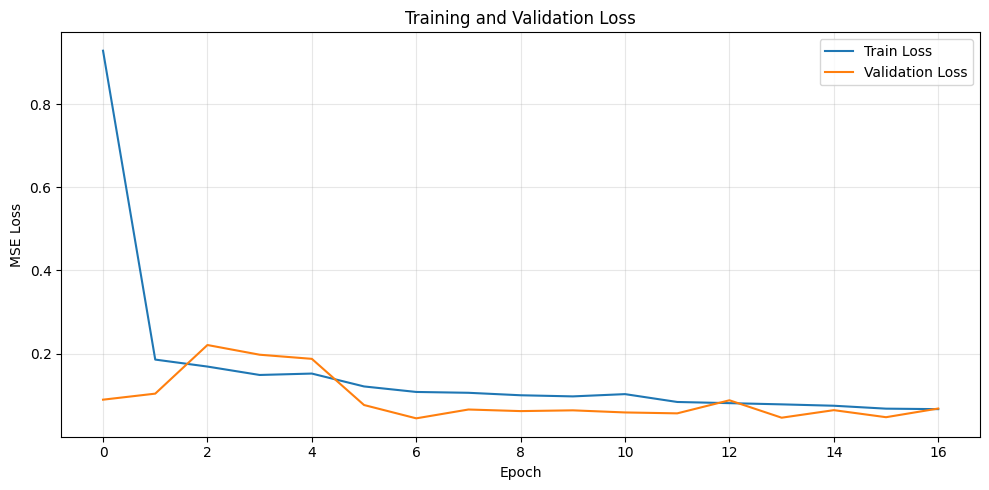

In [64]:
# Training / Validation loss curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


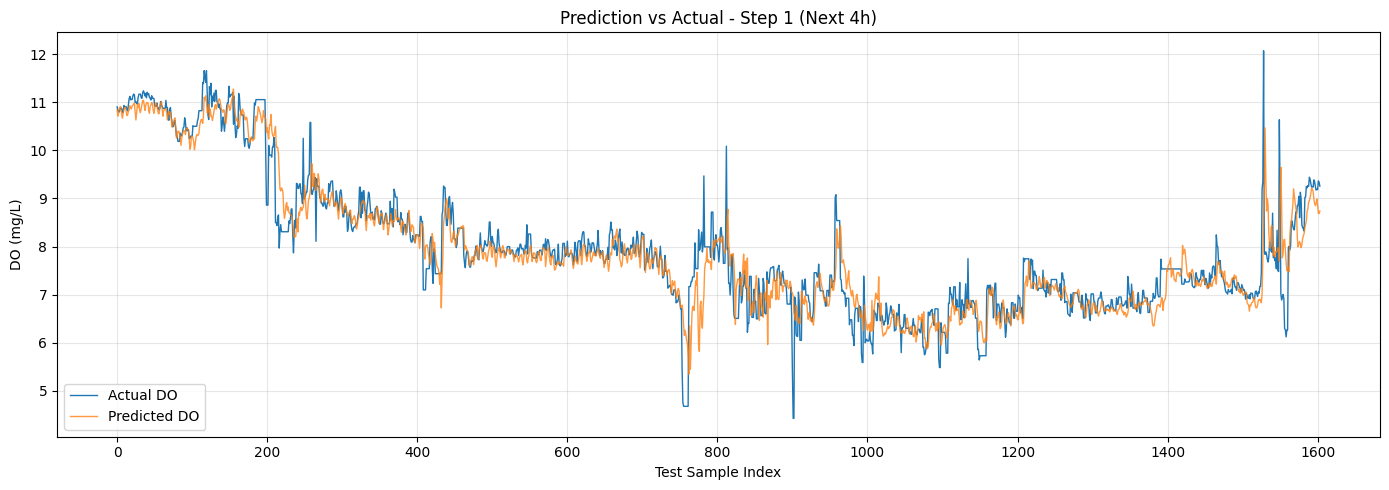

In [65]:
# Prediction vs Actual for the 1-step-ahead forecast across the test set
plt.figure(figsize=(14, 5))
plt.plot(targets[:, 0], label="Actual DO", linewidth=1)
plt.plot(preds[:, 0], label="Predicted DO", linewidth=1, alpha=0.8)
plt.xlabel("Test Sample Index")
plt.ylabel("DO (mg/L)")
plt.title("Prediction vs Actual - Step 1 (Next 4h)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


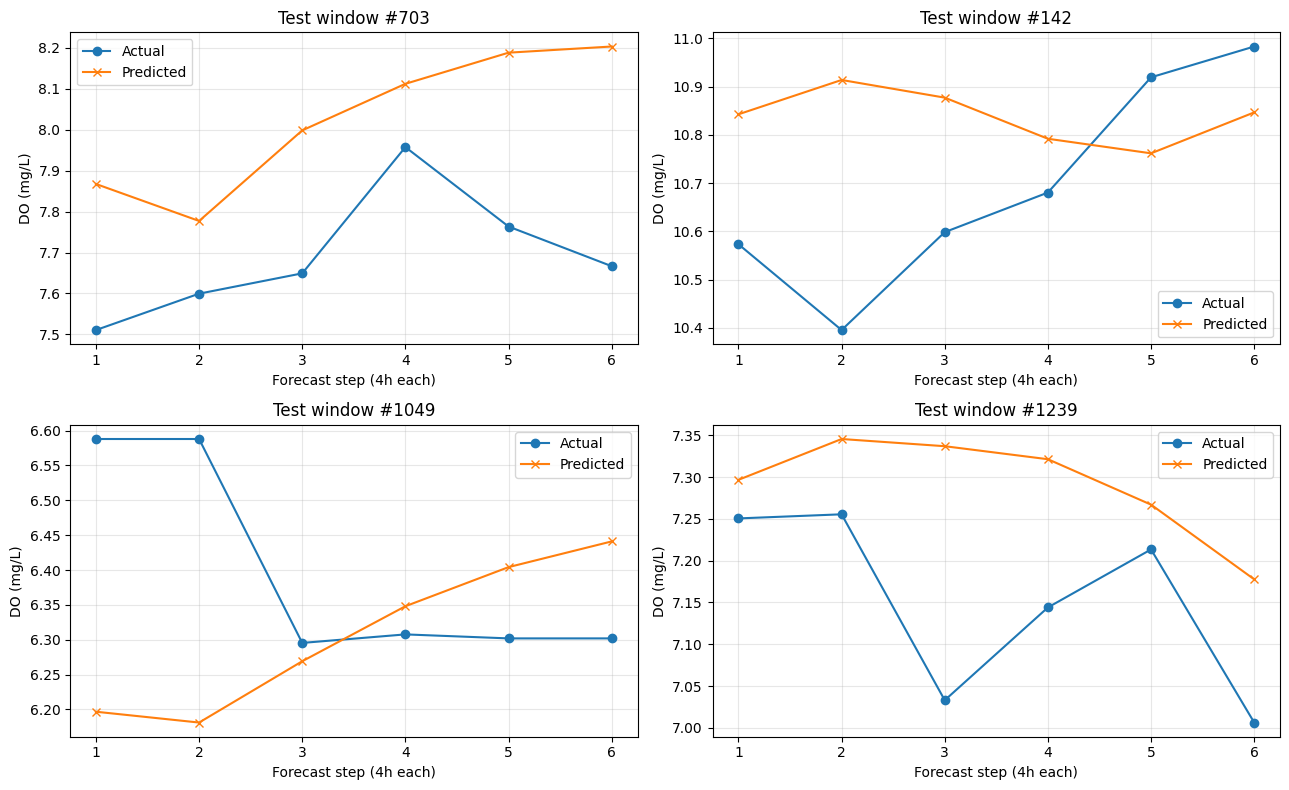

In [66]:
# Multi-step example: visualize a few random forecast windows
rng = np.random.default_rng(SEED)
sample_idxs = rng.choice(len(preds), size=min(4, len(preds)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, idx in zip(axes.flatten(), sample_idxs):
    ax.plot(range(1, HORIZON + 1), targets[idx], marker="o", label="Actual")
    ax.plot(range(1, HORIZON + 1), preds[idx], marker="x", label="Predicted")
    ax.set_title(f"Test window #{idx}")
    ax.set_xlabel("Forecast step (4h each)")
    ax.set_ylabel("DO (mg/L)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


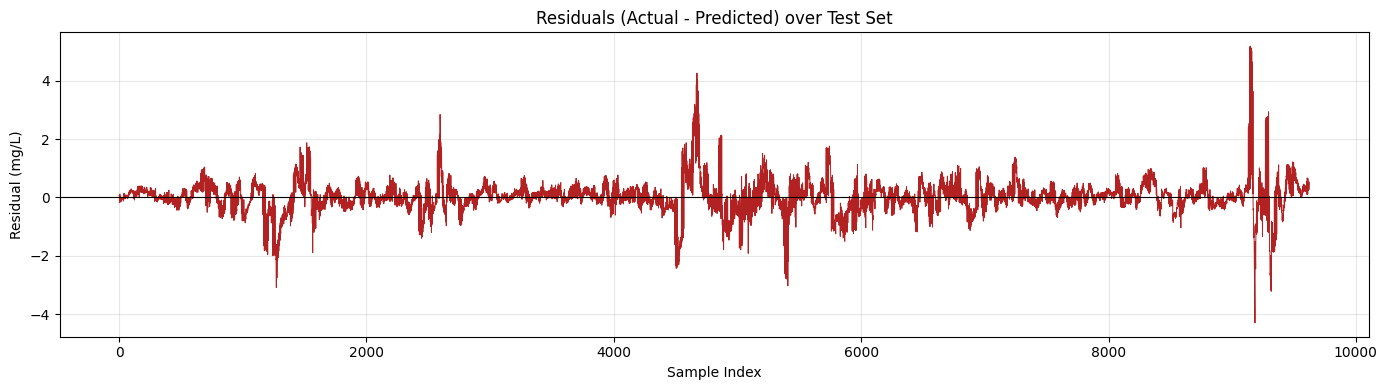

In [67]:
# Residual plot
residuals = targets.reshape(-1) - preds.reshape(-1)
plt.figure(figsize=(14, 4))
plt.plot(residuals, linewidth=0.7, color="firebrick")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Residuals (Actual - Predicted) over Test Set")
plt.xlabel("Sample Index")
plt.ylabel("Residual (mg/L)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


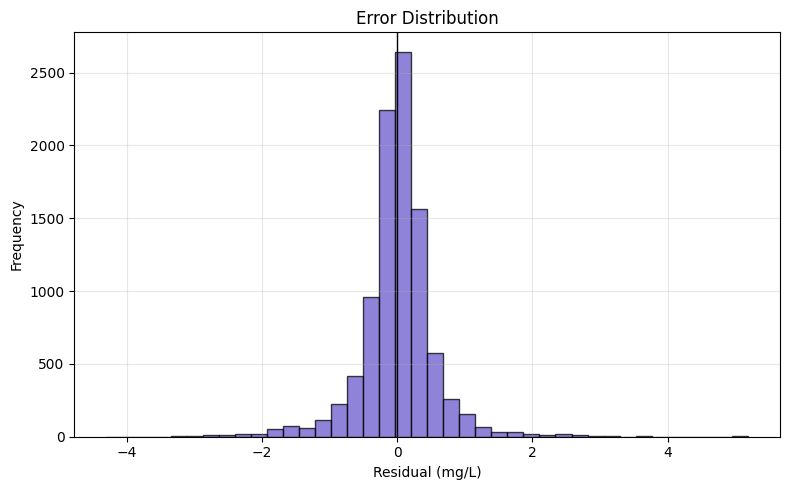

In [68]:
# Error distribution
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40, color="slateblue", edgecolor="black", alpha=0.75)
plt.axvline(0, color="black", linewidth=1)
plt.title("Error Distribution")
plt.xlabel("Residual (mg/L)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [69]:
os.makedirs("outputs", exist_ok=True)

# Best model already saved to best_autoformer_do.pt; copy into outputs/
import shutil
shutil.copy("best_autoformer_do.pt", "outputs/best_autoformer_do.pt")

# Predictions
np.savez("outputs/predictions.npz", preds=preds, targets=targets)

# Metrics JSON
metrics_json = {
    "overall": overall_metrics,
    "per_step": per_step_df.to_dict(orient="records"),
    "training_time_minutes": total_train_time / 60,
    "epochs_trained": len(train_losses),
}
with open("outputs/metrics.json", "w") as f:
    pyjson.dump(metrics_json, f, indent=2)

# Plots
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss"); plt.title("Training and Validation Loss")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("outputs/loss_curve.png", dpi=150)
plt.close()

plt.figure(figsize=(14, 5))
plt.plot(targets[:, 0], label="Actual DO", linewidth=1)
plt.plot(preds[:, 0], label="Predicted DO", linewidth=1, alpha=0.8)
plt.xlabel("Test Sample Index"); plt.ylabel("DO (mg/L)")
plt.title("Prediction vs Actual - Step 1"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/pred_vs_actual.png", dpi=150)
plt.close()

print("Saved to ./outputs/:")
for f in os.listdir("outputs"):
    print(" -", f)

# Optional: download the outputs folder as a zip in Colab
# !zip -r outputs.zip outputs
# files.download("outputs.zip")


Saved to ./outputs/:
 - pred_vs_actual.png
 - best_autoformer_do.pt
 - metrics.json
 - loss_curve.png
 - predictions.npz
